# Error poster: frozen-model training and held-out examples

The [local interactive poster](http://127.0.0.1:8765/) shows full questions and both
answers, ranked by calibrated log loss. This notebook preserves aggregate results
and example IDs without copying competition text into Git.

Training coverage is a fixed uniform **2,048-row sample of 45,985 training-partition
rows** (seed 20261111), selected before scoring. Development and local confirmation
each cover **all 5,746 rows**. Highest-loss training examples mean highest within the
scored sample. The model completed only 0.61 epochs and per-row exposure was not
logged. Local confirmation is not Kaggle's hidden test set; inspecting it now
precludes treating it as untouched for future qualitative choices.


In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
repo = Path.cwd()
if repo.name == 'notebooks': repo = repo.parent
summary = json.loads((repo/'results/error_poster_002/summary.json').read_text())
assert not summary['preview'], 'Wait for training-sample inference and rebuild the poster'
html_path = Path(summary['path'])
data = json.loads(html_path.read_text().split('<script type="application/json" id="poster-data">',1)[1].split('</script>',1)[0])
cohorts = pd.DataFrame([{'cohort': c['title'], **c['metrics']} for c in summary['cohorts']]).set_index('cohort')
display(cohorts.round(5))
print('Frozen adapter:', summary['model_hash'])
print('Temperature:', summary['temperature'])
print('Official Kaggle log loss:', summary['official_score'])
print('Selected gallery examples:', summary['gallery_cases'])


,rows,log_loss,accuracy,balanced_accuracy,macro_f1,brier
cohort,,,,,,
Training sample,2048,0.96566,0.55273,0.55093,0.55083,0.57308
Development,5746,0.96883,0.52732,0.52474,0.52461,0.57767
Held-out test (local),5746,0.96236,0.53063,0.52883,0.52889,0.57318


Frozen adapter: 8afc09d728698c7bcd02e47f9d427166b4b07b3644c848052cc66c9b4f08e39d
Temperature: 0.7220597450036835
Official Kaggle log loss: 0.97025
Selected gallery examples: 427


Each row contributes **−ln(P(observed human choice))**. A confident wrong
decision therefore contributes more loss than an uncertain one. Original/swapped
probabilities are aligned and averaged before the frozen temperature is applied.
Saved training and confirmation probabilities are already calibrated; development
is calibrated once when building the poster. No new model was trained or submitted.

The sample and full-fold means have different sampling uncertainty. A small gap
alone cannot diagnose underfitting or overfitting, especially after partial training.


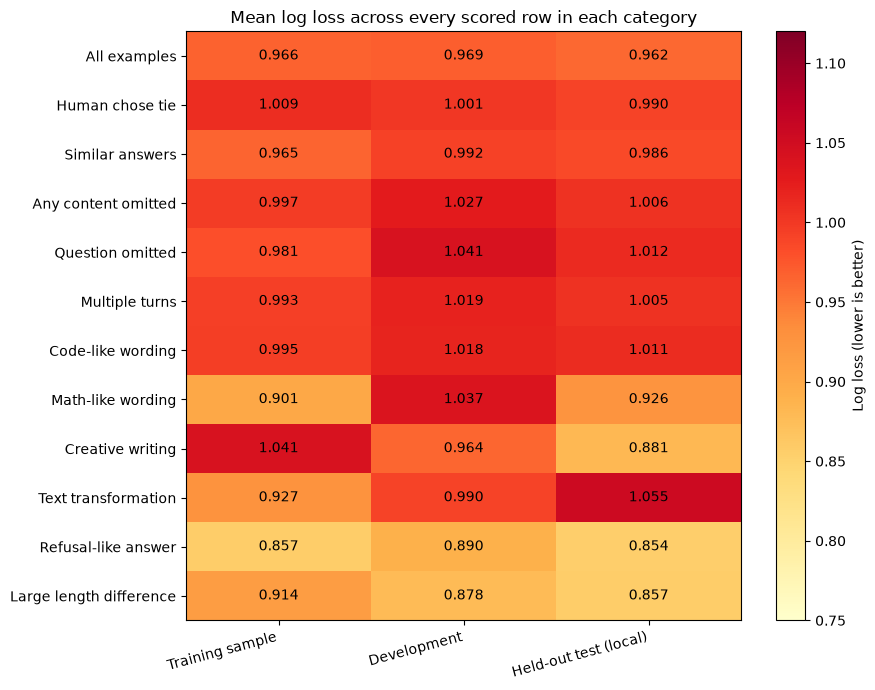

,Training sample,Development,Held-out test (local)
All examples,2048,5746,5746
Human chose tie,635,1775,1776
Similar answers,411,1201,1209
Any content omitted,413,1152,1173
Question omitted,163,418,463
Multiple turns,260,809,767
Code-like wording,195,549,559
Math-like wording,31,95,130
Creative writing,132,419,428
Text transformation,94,246,263


In [2]:
keys = ['all','true_tie','similar_answers','truncated','prompt_cut','multi_turn','code','math','creative','transformation','refusal','length_gap']
categories = {c['key']: c for c in summary['categories']}
matrix = pd.DataFrame({c['title']: {categories[k]['title']: categories[k]['cohort_metrics'].get(c['key'],{}).get('log_loss',np.nan) for k in keys} for c in summary['cohorts']})
fig, ax = plt.subplots(figsize=(9,7))
image = ax.imshow(matrix.to_numpy(), cmap='YlOrRd', vmin=.75, vmax=1.12, aspect='auto')
ax.set_xticks(range(len(matrix.columns)), matrix.columns, rotation=15, ha='right')
ax.set_yticks(range(len(matrix.index)), matrix.index)
for i in range(len(matrix)):
    for j in range(len(matrix.columns)):
        ax.text(j,i,f'{matrix.iloc[i,j]:.3f}',ha='center',va='center')
ax.set_title('Mean log loss across every scored row in each category')
fig.colorbar(image, ax=ax, label='Log loss (lower is better)')
fig.tight_layout()
plt.show()
display(pd.DataFrame({c['title']: {categories[k]['title']: categories[k]['cohort_counts'][c['key']] for k in keys} for c in summary['cohorts']}))


Categories overlap. Task tags are lexical cues and can have false positives;
non-ASCII is not a language label. The order-sensitive category is observed only
where raw original/swapped predictions were retained: the training sample and the
512-row development pilot. Unmeasured does not mean order-invariant. Context
comparisons exist only in the development pilot.


In [3]:
cases = pd.DataFrame([{k: c[k] for k in ['id','key','cohort','label','prediction','loss','confidence','cohort_rank']} for c in data['cases']])
cases['human'] = cases.label.map({0:'A',1:'B',2:'Tie'})
cases['model'] = cases.prediction.map({0:'A',1:'B',2:'Tie'})
cases['probability_of_human_choice'] = np.exp(-cases.loss)
display(cases.sort_values(['cohort','loss','id'], ascending=[True,False,True]).groupby('cohort',sort=False).head(8)[['cohort','id','cohort_rank','human','model','loss','probability_of_human_choice']].round(5))


,cohort,id,cohort_rank,human,model,loss,probability_of_human_choice
195,dev,1568170498,1,B,A,3.71564,0.02434
166,dev,836802513,2,B,A,3.43731,0.03215
191,dev,1485267511,3,B,A,3.38256,0.03396
219,dev,2106457410,4,B,A,3.29335,0.03713
136,dev,91135016,5,A,B,3.23574,0.03933
181,dev,1152956056,6,B,A,3.22436,0.03978
252,dev,2919728403,7,A,B,3.22343,0.03982
276,dev,3780592340,8,A,B,3.17695,0.04171
409,test,3885487475,1,A,B,3.57783,0.02794
334,test,1012843597,2,B,A,3.47802,0.03087


The poster contains the union of the top 12 examples per category and cohort,
deduplicated. Search, sorting and pagination operate on that selected gallery;
cohort/category summary metrics use all scored rows. The largest individual errors
do not necessarily explain most total loss.

Use the reviewed cases as starting points: missing source material and ambiguous
requests, factual/constraint checks, and subjective style or tie decisions. Analyst
notes distinguish observation from hypothesis and suggest controlled follow-ups.
They do not automatically replace observed votes or establish cause prevalence.


In [4]:
notes = json.loads((repo/'results/error_poster_002/review_notes.json').read_text())
display(pd.DataFrame(notes)[['id','theme','observation','interpretation','next_test']])


,id,theme,observation,interpretation,next_test
0,171385530,Training example: premature solution before so...,The user plans to send two MATLAB scripts for ...,A visible missing-input issue also appears in ...,Build a development diagnostic for requests re...
1,1614422858,Training example: human prefers refusal to a c...,A supplies a story in response to a historical...,Completion and fluency are insufficient to pre...,Review refusal-versus-completion comparisons b...
2,4046915852,Training example: tie vote despite strongly co...,A gives a detailed response to a socially char...,The tie class does not come with a reason for ...,Inspect high-confidence tie misses across many...
3,1012843597,Ambiguous request: detailed completion versus ...,The question has no referent. A chooses a part...,This example is consistent with rewarding a fl...,Evaluate a development set of ambiguous reques...
4,2313946712,Missing source text: invented rewrite preferre...,The user asks for a concise humorous rewrite b...,The visible input supports a concrete relevanc...,Test grounded instruction-compliance features ...
5,714853521,Both answers plausible: strong preference may ...,Both answers discuss support for software-deve...,"Possible verbosity/style overconfidence, rathe...",Measure confidence on similar-quality answer p...
6,726880185,"Subjective prioritization: label is a vote, no...",One answer declines to prioritize between two ...,The preferred style is debatable. This case il...,Audit preference uncertainty and confidence by...


To rebuild and browse (all frozen artifacts must already be available):

```bash
uv run --extra train python scripts/build_error_poster.py
uv run python scripts/serve_error_poster.py
```

Open http://127.0.0.1:8765/. The standalone HTML is stored under
`~/database/llm_classification_finetuning/eda/attempt_002/poster/site/index.html`.
Notes stay in browser storage until exported. Code, aggregate evidence and this
executed notebook are in Git; full-text HTML and screenshots stay under `~/database`.
